# 03 · Who responds? Meta-learners vs causal forest, Qini/AUUC/RATE, policy value

The pipeline fits S/T/X/R/DR-learners and `CausalForestDML` with 4-fold × 2-repeat cross-fitting
(≈ 2 minutes); this notebook reads the saved out-of-fold scores and re-derives every metric from them.

Read with: [`05_meta_learners_s_t_x.md`](../docs/learn/05_meta_learners_s_t_x.md),
[`06_r_learner_dr_learner.md`](../docs/learn/06_r_learner_dr_learner.md),
[`07_causal_forests.md`](../docs/learn/07_causal_forests.md),
[`08_evaluating_uplift_qini_auuc_rate.md`](../docs/learn/08_evaluating_uplift_qini_auuc_rate.md),
[`09_policy_learning.md`](../docs/learn/09_policy_learning.md).

In [1]:
import json, warnings
from pathlib import Path
import numpy as np, pandas as pd
from IPython.display import Image, display
warnings.filterwarnings("ignore")
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30); pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
from tierlift.config import REPO_ROOT, load_config
from tierlift.simulate import SimulatedData
cfg = load_config()
DATA, RESULTS, FIGS = REPO_ROOT / "data", REPO_ROOT / "results", REPO_ROOT / "reports" / "figures"
assert DATA.exists(), "run `make all` (or `tierlift run-all`) first: the notebooks read data/ and results/"
data = SimulatedData.load(DATA)
e, truth = data.experiment, data.truth.set_index("client_id")
primary, control = cfg.analysis.primary_contrast
def fig(name): display(Image(filename=str(FIGS / name), width=900))
print(f"seed {cfg.seed}, {len(e):,} clients, cells {cfg.experiment.cells}")

seed 13, 5,000 clients, cells {'holdout': 0.3, 'nudge': 0.3, 'incentive': 0.4}


In [2]:
from tierlift.features import build_features
from tierlift.uplift.evaluate import qini_curve, auuc, qini_coefficient, rate, blp_calibration, oracle_metrics, perfect_ranking_auuc
scores = pd.read_parquet(DATA / "uplift_scores.parquet")
s = e[e["cell"].isin([primary, control])].reset_index(drop=True); d = (s["cell"] == primary).to_numpy()
assert (scores.index.to_numpy() == s["client_id"].to_numpy()).all()
y_index = (s["exp_revenue"] / s["pre_revenue"]).to_numpy()
models = [c for c in scores.columns if c != "true_ite_index"]
print(models)

['S-learner', 'T-learner', 'X-learner', 'R-learner', 'DR-learner', 'CausalForestDML']


## 1. The leaderboard, recomputed from the out-of-fold scores

In [3]:
rows = []
for m in models:
    tau = scores[m].to_numpy()
    r = rate(tau, y_index, d, n_bootstrap=100, seed=cfg.seed); b = blp_calibration(tau, y_index, d)
    rows.append({"model": m, "qini": qini_coefficient(tau, y_index, d), "auuc": auuc(tau, y_index, d), "rate_autoc": r["autoc"], "rate_p": r["p_value"],
                 "blp_slope": b["heterogeneity_coef"], **oracle_metrics(tau, scores["true_ite_index"].to_numpy())})
lb = pd.DataFrame(rows).set_index("model").sort_values("auuc", ascending=False); display(lb)
print("AUUC of a model that knew the truth:", round(perfect_ranking_auuc(scores["true_ite_index"].to_numpy(), y_index, d), 4))

,qini,auuc,rate_autoc,rate_p,blp_slope,pehe,spearman_vs_truth,pearson_vs_truth
model,,,,,,,,
CausalForestDML,0.0134,0.0234,0.0712,0.0008,1.9141,0.0916,0.7039,0.5894
X-learner,0.0108,0.0188,0.0680,0.0061,0.7120,0.1053,0.4544,0.5252
S-learner,0.0106,0.0185,0.0688,0.0011,1.7005,0.0901,0.6587,0.6436
T-learner,0.0066,0.0117,0.0386,0.0720,0.5493,0.1292,0.3868,0.4380
R-learner,0.0064,0.0112,0.0340,0.1056,0.6262,0.1440,0.3583,0.4032
DR-learner,0.0059,0.0104,0.0196,0.2366,0.4552,0.1484,0.3463,0.3705


AUUC of a model that knew the truth: 0.0357


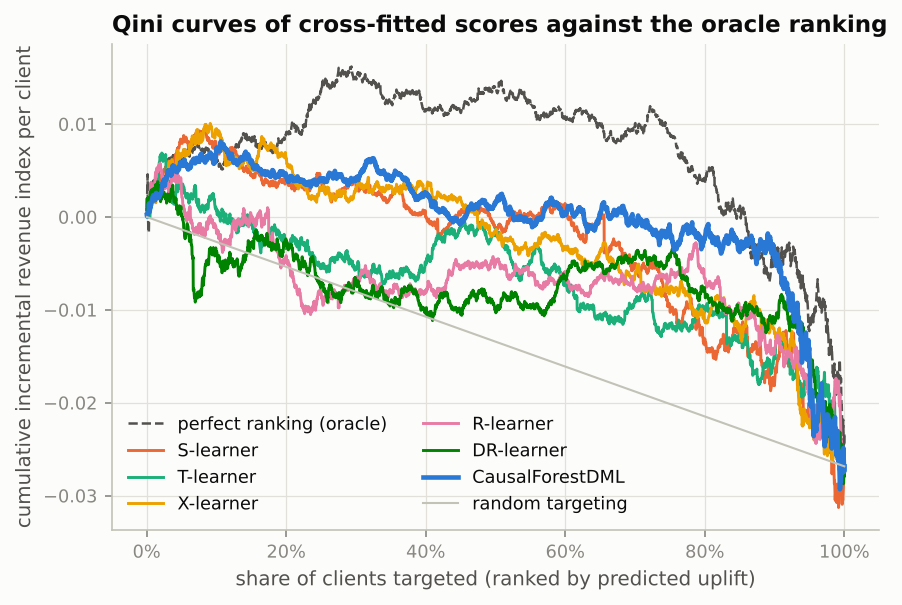

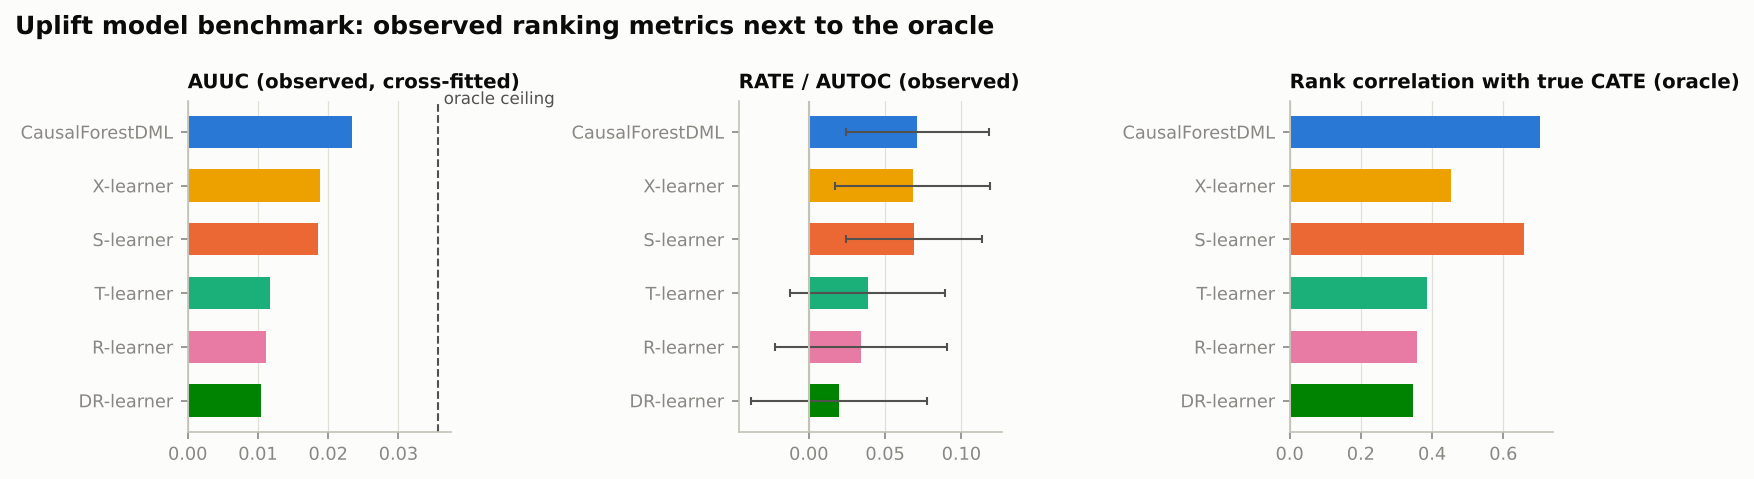

In [4]:
fig("05_qini_curves.png"); fig("06_uplift_benchmark.png")

## 2. Does the forest see the band? CATE vs distance to the next tier

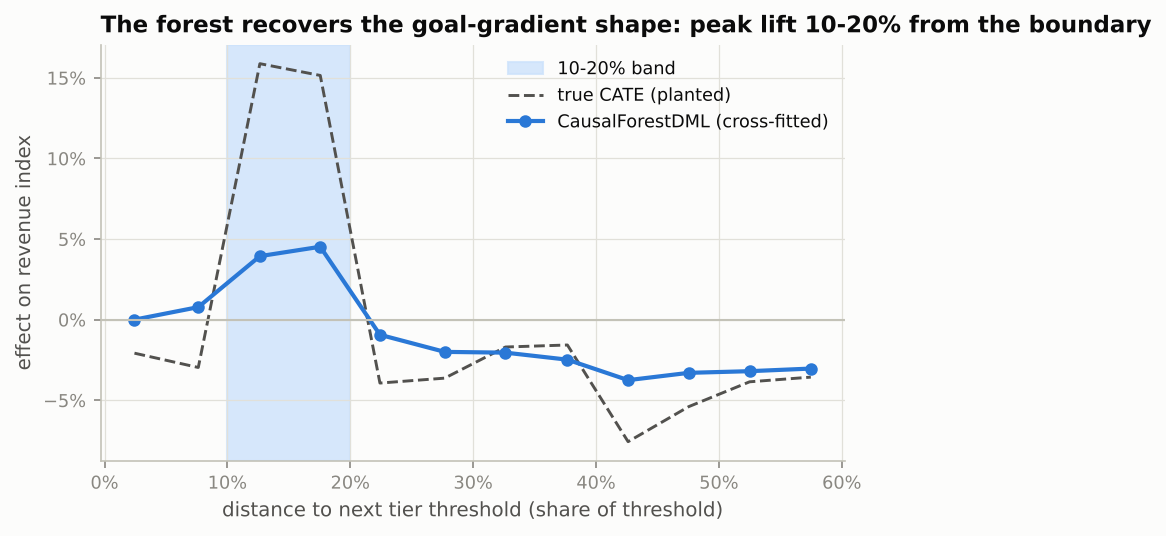

,cf,truth
distance_bucket,,
10_to_20,+0.042,+0.155
20_plus,-0.030,-0.038
top_tier,-0.026,+0.017
within_10,+0.004,-0.025


In [5]:
fig("07_cate_vs_distance.png")
sc = s.assign(cf=scores["CausalForestDML"].to_numpy(), truth=scores["true_ite_index"].to_numpy())
display(sc.groupby("distance_bucket")[["cf", "truth"]].mean().style.format("{:+.3f}"))

## 3. Stability across replications

`tierlift montecarlo --benchmark` re-simulates and re-fits the zoo on several seeds (reduced settings).

In [6]:
p = RESULTS / "benchmark_montecarlo_summary.csv"
display(pd.read_csv(p, index_col=0) if p.exists() else "run `tierlift montecarlo --benchmark --n-seeds 5`")

,mean_auuc,sd_auuc,mean_auuc_rank,share_first_by_auuc,mean_rate_autoc,mean_spearman_vs_truth,mean_spearman_rank,mean_pehe,mean_blp_slope
model,,,,,,,,,
S-learner,0.0133,0.0123,2.4000,0.6000,0.0544,0.5633,2.0000,0.0844,1.0936
R-learner,0.0117,0.0173,2.8000,0.2000,0.0498,0.3187,4.8000,0.1530,0.2998
CausalForestDML,0.0105,0.0125,3.0000,0.0000,0.0434,0.5989,1.0000,0.0875,0.9283
X-learner,0.0094,0.0159,3.8000,0.0000,0.0420,0.3861,3.0000,0.1098,0.3980
DR-learner,0.0087,0.0165,4.2000,0.2000,0.0358,0.3074,5.4000,0.1502,0.2145
T-learner,0.0082,0.0135,4.8000,0.0000,0.0370,0.3270,4.8000,0.1401,0.3040


## 4. From scores to a decision: policy values with doubly robust scores

,value_per_client,se,share_targeted,total_value
Blanket rollout,"-2,209.1220",903.9278,1.0000,"-7,736,345.1858"
Rule: 10-20% from tier,549.8847,201.4327,0.0820,"1,925,696.0995"
CATE > 0: S-learner,645.0511,167.0535,0.1836,"2,258,969.0286"
CATE > 0: T-learner,170.3325,450.5492,0.4003,"596,504.3377"
CATE > 0: X-learner,43.2593,433.6048,0.3649,"151,493.9012"
CATE > 0: R-learner,-448.8016,514.9688,0.3903,"-1,571,703.2977"
CATE > 0: DR-learner,-183.7312,526.5040,0.3906,"-643,426.5194"
CATE > 0: CausalForestDML,592.8713,164.0093,0.2005,"2,076,235.3369"
"DR policy tree (depth 2, in-sample)",642.1809,206.4706,0.1725,"2,248,917.4110"
"DR policy tree (depth 2, cross-fitted)",-886.2677,604.9782,0.3561,"-3,103,709.5107"


|--- distance_pct_filled <= 0.20
|   |--- maker_ratio <= 0.43
|   |   |--- class: 1
|   |--- maker_ratio >  0.43
|   |   |--- class: 0
|--- distance_pct_filled >  0.20
|   |--- log_pre_volume <= 16.36
|   |   |--- class: 1
|   |--- log_pre_volume >  16.36
|   |   |--- class: 0



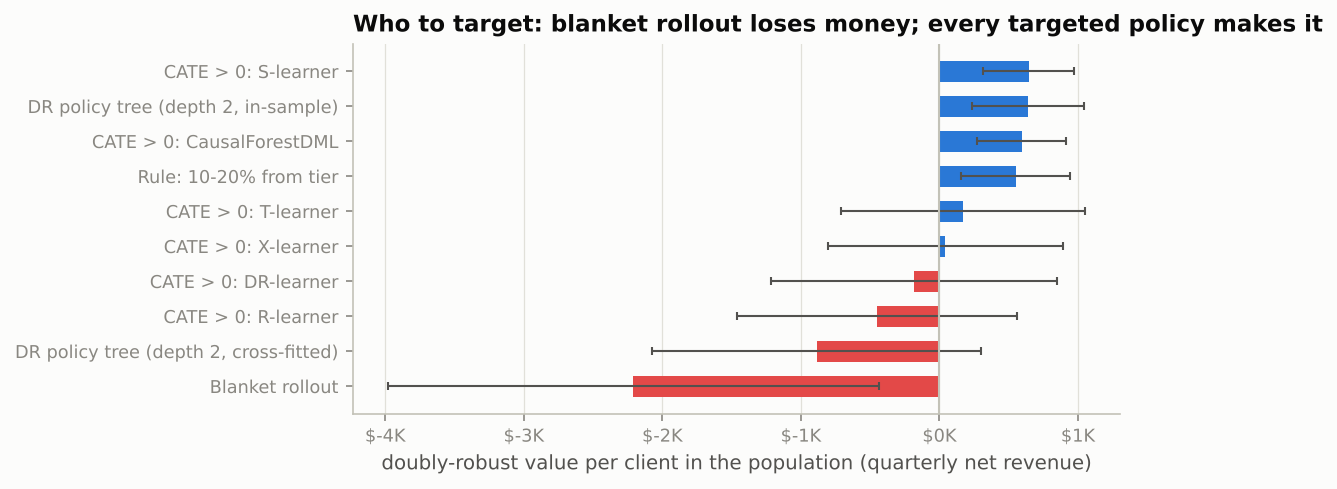

In [7]:
display(pd.read_csv(RESULTS / "policy_comparison.csv", index_col=0))
print((RESULTS / "policy_tree.txt").read_text())
fig("08_policy_values.png")

## Check your understanding

1. Rank the six models by `spearman_vs_truth` and by `auuc`. Where do the orders disagree, and what does the bootstrap SE of RATE say about whether that disagreement is real?
2. The S-learner's BLP slope is ≈ 1.7. Is it too bold or too timid? Would you trust its τ̂ as a dollar forecast?
3. The policy tree's in-sample value is positive and its cross-fitted value is not. Which number would you put in a slide, and what does the gap measure?